In [1]:
!pip install -q timm
!pip install -q albumentations
!pip install -q opencv-python
!pip install -q imbalanced-learn
!pip install -q torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 43.6 MB/s eta 0:00:00


In [2]:
import kagglehub

path = kagglehub.dataset_download(
    "andrewmvd/isic-2019"
)

print(path)

/kaggle/input/datasets/andrewmvd/isic-2019


In [3]:
import os
import pandas as pd

csv_files = []

for root, dirs, files in os.walk(path):
    for f in files:
        if f.endswith(".csv"):
            csv_files.append(
                os.path.join(root, f)
            )

print(csv_files)

['/kaggle/input/datasets/andrewmvd/isic-2019/ISIC_2019_Training_GroundTruth.csv', '/kaggle/input/datasets/andrewmvd/isic-2019/ISIC_2019_Training_Metadata.csv']


In [9]:
label_path = [f for f in csv_files if "GroundTruth" in f][0]

label_df = pd.read_csv(label_path)

label_df["target"] = (
    label_df["MEL"] == 1
).astype(int)

In [10]:
metadata_path = [f for f in csv_files if "Metadata" in f][0]

meta_df = pd.read_csv(
    metadata_path
)

In [11]:
df = pd.merge(
    meta_df,
    label_df,
    on="image",
    how="inner"
)

print(df.shape)

(25331, 15)


In [12]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

In [13]:
df["age_approx"] = df["age_approx"].fillna(
    df["age_approx"].median()
)

df["sex"] = df["sex"].fillna(
    "unknown"
)

df["anatom_site_general"] = (
    df["anatom_site_general"]
    .fillna("unknown")
)

In [14]:
sex_encoder = LabelEncoder()
site_encoder = LabelEncoder()

df["sex"] = sex_encoder.fit_transform(
    df["sex"]
)

df["anatom_site_general"] = (
    site_encoder.fit_transform(
        df["anatom_site_general"]
    )
)

In [15]:
scaler = StandardScaler()

df["age_approx"] = scaler.fit_transform(
    df[["age_approx"]]
)

In [16]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

In [17]:
model_df = df[
    [
        "image",
        "age_approx",
        "sex",
        "anatom_site_general",
        "target"
    ]
]

In [18]:
rus = RandomUnderSampler(
    sampling_strategy=0.5,
    random_state=42
)

X_under, y_under = rus.fit_resample(
    model_df.drop(
        "target",
        axis=1
    ),
    model_df["target"]
)

In [19]:
ros = RandomOverSampler(
    random_state=42
)

X_balanced, y_balanced = ros.fit_resample(
    X_under,
    y_under
)

balanced_df = X_balanced.copy()

balanced_df["target"] = y_balanced

In [20]:
import cv2
import numpy as np

In [21]:
def hair_removal(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (17,17)
    )

    blackhat = cv2.morphologyEx(
        gray,
        cv2.MORPH_BLACKHAT,
        kernel
    )

    _, mask = cv2.threshold(
        blackhat,
        10,
        255,
        cv2.THRESH_BINARY
    )

    image = cv2.inpaint(
        image,
        mask,
        1,
        cv2.INPAINT_TELEA
    )

    return image

In [22]:
def apply_clahe(image):

    lab = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2LAB
    )

    l,a,b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2,
        tileGridSize=(8,8)
    )

    l = clahe.apply(l)

    lab = cv2.merge([l,a,b])

    image = cv2.cvtColor(
        lab,
        cv2.COLOR_LAB2RGB
    )

    return image

In [23]:
import albumentations as A

from albumentations.pytorch import (
    ToTensorV2
)

In [24]:
train_transform = A.Compose([

    A.Resize(224,224),

    A.HorizontalFlip(p=0.5),

    A.VerticalFlip(p=0.5),

    A.Rotate(limit=30,p=0.5),

    A.RandomBrightnessContrast(p=0.3),

    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),

    ToTensorV2()

])

In [25]:
val_transform = A.Compose([

    A.Resize(224,224),

    A.Normalize(
        mean=(0.485,0.456,0.406),
        std=(0.229,0.224,0.225)
    ),

    ToTensorV2()

])

In [26]:
from torch.utils.data import Dataset
import torch

In [27]:
class ISICDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_dir,
        transform=None
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.image_dir = image_dir

        self.transform = transform

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = os.path.join(
            self.image_dir,
            row["image"] + ".jpg"
        )

        image = cv2.imread(
            image_path
        )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        image = hair_removal(
            image
        )

        image = apply_clahe(
            image
        )

        image = self.transform(
            image=image
        )["image"]

        metadata = torch.tensor(
            [
                row["age_approx"],
                row["sex"],
                row["anatom_site_general"]
            ],
            dtype=torch.float
        )

        label = torch.tensor(
            row["target"],
            dtype=torch.long
        )

        return image, metadata, label

In [29]:
from sklearn.model_selection import (
    train_test_split
)

In [30]:
train_df, val_df = train_test_split(
    balanced_df,
    test_size=0.2,
    stratify=balanced_df["target"],
    random_state=42
)

In [31]:

IMAGE_DIR = "/kaggle/input/datasets/andrewmvd/isic-2019/ISIC_2019_Training_Input/ISIC_2019_Training_Input"

In [32]:
train_dataset = ISICDataset(
    train_df,
    IMAGE_DIR,
    train_transform
)

val_dataset = ISICDataset(
    val_df,
    IMAGE_DIR,
    val_transform
)

In [33]:
img, meta, label = train_dataset[0]

print(img.shape)
print(meta.shape)
print(label)

torch.Size([3, 224, 224])
torch.Size([3])
tensor(0)


In [38]:
from torch_geometric.data import Data
from torch_geometric.data import Batch

In [39]:
def create_graph(metadata):

    age = metadata[0]
    sex = metadata[1]
    site = metadata[2]

    x = torch.tensor(
        [
            [age],
            [sex],
            [site]
        ],
        dtype=torch.float
    )

    edge_index = torch.tensor(
        [
            [0,0,1,1,2,2],
            [1,2,0,2,0,1]
        ],
        dtype=torch.long
    )

    return Data(
        x=x,
        edge_index=edge_index
    )

In [40]:
sample_graph = create_graph(meta)

print(sample_graph)
print(sample_graph.x.shape)

Data(x=[3, 1], edge_index=[2, 6])
torch.Size([3, 1])


In [41]:
def collate_fn(batch):

    images = []
    graphs = []
    labels = []

    for image, metadata, label in batch:

        images.append(image)

        graph = create_graph(
            metadata.numpy()
        )

        graphs.append(graph)

        labels.append(label)

    images = torch.stack(images)

    labels = torch.tensor(labels)

    graph_batch = Batch.from_data_list(
        graphs
    )

    return (
        images,
        graph_batch,
        labels
    )

In [42]:
from torch.utils.data import DataLoader

In [47]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

In [48]:
images, graph_batch, labels = next(
    iter(train_loader)
)

print(images.shape)
print(graph_batch.x.shape)
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([96, 1])
torch.Size([32])


In [49]:
print(graph_batch.edge_index.shape)
print(graph_batch.batch.shape)

torch.Size([2, 192])
torch.Size([96])


In [54]:
import timm

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import SAGEConv
from torch_geometric.nn import global_mean_pool

In [55]:
class GraphMetadataEncoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.conv1 = SAGEConv(
            in_channels=1,
            out_channels=32
        )

        self.conv2 = SAGEConv(
            in_channels=32,
            out_channels=64
        )

        self.fc = nn.Linear(
            64,
            128
        )

    def forward(
        self,
        x,
        edge_index,
        batch
    ):

        x = self.conv1(
            x,
            edge_index
        )

        x = F.relu(x)

        x = self.conv2(
            x,
            edge_index
        )

        x = F.relu(x)

        x = global_mean_pool(
            x,
            batch
        )

        x = self.fc(x)

        return x

In [56]:
class ConvNeXtEncoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.backbone = timm.create_model(
            "convnext_tiny",
            pretrained=True,
            num_classes=0
        )

    def forward(self, x):

        x = self.backbone(x)

        return x

In [57]:
class FusionClassifier(nn.Module):

    def __init__(self):

        super().__init__()

        self.fc1 = nn.Linear(
            896,
            512
        )

        self.bn1 = nn.BatchNorm1d(
            512
        )

        self.fc2 = nn.Linear(
            512,
            128
        )

        self.bn2 = nn.BatchNorm1d(
            128
        )

        self.fc3 = nn.Linear(
            128,
            2
        )

        self.dropout = nn.Dropout(
            0.3
        )

    def forward(self, x):

        x = self.fc1(x)

        x = self.bn1(x)

        x = F.relu(x)

        x = self.dropout(x)

        x = self.fc2(x)

        x = self.bn2(x)

        x = F.relu(x)

        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [60]:
class SkinCancerNet(nn.Module):

    def __init__(self):

        super().__init__()

        self.image_encoder = ConvNeXtEncoder()

        self.graph_encoder = GraphMetadataEncoder()

        self.classifier = FusionClassifier()

    def forward(
        self,
        images,
        node_features,
        edge_index,
        batch
    ):

        image_features = self.image_encoder(
            images
        )

        graph_features = self.graph_encoder(
            node_features,
            edge_index,
            batch
        )

        fused = torch.cat(
            [
                image_features,
                graph_features
            ],
            dim=1
        )

        outputs = self.classifier(
            fused
        )

        return outputs

In [61]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model = SkinCancerNet().to(device)

print(model)

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

SkinCancerNet(
  (image_encoder): ConvNeXtEncoder(
    (backbone): ConvNeXt(
      (stem): Sequential(
        (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
        (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
      )
      (stages): Sequential(
        (0): ConvNeXtStage(
          (downsample): Identity()
          (blocks): Sequential(
            (0): ConvNeXtBlock(
              (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
              (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
              (mlp): Mlp(
                (fc1): Linear(in_features=96, out_features=384, bias=True)
                (act): GELU()
                (drop1): Dropout(p=0.0, inplace=False)
                (norm): Identity()
                (fc2): Linear(in_features=384, out_features=96, bias=True)
                (drop2): Dropout(p=0.0, inplace=False)
              )
              (shortcut): Identity()
              (drop_pat

In [ ]:
images, graph_batch, labels = next(
    iter(train_loader)
)

images = images.to(device)

graph_batch = graph_batch.to(device)

outputs = model(
    images,
    graph_batch.x,
    graph_batch.edge_index,
    graph_batch.batch
)

print(outputs.shape)

In [62]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [63]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(train_df["target"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["target"]
)

weights = torch.tensor(
    weights,
    dtype=torch.float
).to(device)

print(weights)

tensor([1., 1.], device='cuda:0')


In [64]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(train_df["target"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["target"]
)

weights = torch.tensor(
    weights,
    dtype=torch.float
).to(device)

print(weights)

tensor([1., 1.], device='cuda:0')


In [65]:
criterion = nn.CrossEntropyLoss(
    weight=weights
)

In [67]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [69]:
class EarlyStopping:

    def __init__(
        self,
        patience=7,
        min_delta=0.001
    ):

        self.patience = patience

        self.min_delta = min_delta

        self.best_auc = 0

        self.counter = 0

        self.early_stop = False

    def __call__(self, auc):

        if auc > self.best_auc + self.min_delta:

            self.best_auc = auc

            self.counter = 0

        else:

            self.counter += 1

            print(
                f"EarlyStopping Counter: {self.counter}"
            )

            if self.counter >= self.patience:

                self.early_stop = True

In [71]:
early_stopping = EarlyStopping(
    patience=7
)

In [72]:
best_auc = 0

In [76]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [78]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    for images, graph_batch, labels in loader:

        images = images.to(device)

        labels = labels.to(device)

        graph_batch = graph_batch.to(device)

        optimizer.zero_grad()

        outputs = model(
            images,
            graph_batch.x,
            graph_batch.edge_index,
            graph_batch.batch
        )

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    return running_loss / len(loader)

In [80]:
def validate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    val_loss = 0

    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():

        for images, graph_batch, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            graph_batch = graph_batch.to(device)

            outputs = model(
                images,
                graph_batch.x,
                graph_batch.edge_index,
                graph_batch.batch
            )

            loss = criterion(
                outputs,
                labels
            )

            val_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )[:,1]

            preds = torch.argmax(
                outputs,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    prec = precision_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    rec = recall_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    auc = roc_auc_score(
        all_labels,
        all_probs
    )

    return (
        val_loss / len(loader),
        acc,
        prec,
        rec,
        f1,
        auc
    )

In [83]:
print(device)

cuda


In [85]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [86]:
print(type(scheduler))

<class 'torch.optim.lr_scheduler.ReduceLROnPlateau'>


In [87]:
print("model:", "model" in globals())
print("optimizer:", "optimizer" in globals())
print("criterion:", "criterion" in globals())
print("scheduler:", "scheduler" in globals())
print("early_stopping:", "early_stopping" in globals())

model: True
optimizer: True
criterion: True
scheduler: True
early_stopping: True


In [88]:
num_epochs = 30

best_auc = 0

for epoch in range(num_epochs):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    (
        val_loss,
        acc,
        prec,
        rec,
        f1,
        auc
    ) = validate(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(auc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Acc: {acc:.4f} "
        f"Prec: {prec:.4f} "
        f"Recall: {rec:.4f} "
        f"F1: {f1:.4f} "
        f"AUC: {auc:.4f}"
    )

    if auc > best_auc:

        best_auc = auc

        torch.save(
            model.state_dict(),
            "best_model.pth"
        )

        print(
            "Best Model Saved"
        )

    early_stopping(auc)

    if early_stopping.early_stop:

        print(
            "Early stopping triggered"
        )

        break

Epoch [1/30] Train Loss: 0.4033 Val Loss: 0.4071 Acc: 0.8104 Prec: 0.7640 Recall: 0.8983 F1: 0.8257 AUC: 0.9035
Best Model Saved
Epoch [2/30] Train Loss: 0.3716 Val Loss: 0.3663 Acc: 0.8206 Prec: 0.8994 Recall: 0.7219 F1: 0.8010 AUC: 0.9277
Best Model Saved
Epoch [3/30] Train Loss: 0.3385 Val Loss: 0.3348 Acc: 0.8510 Prec: 0.8159 Recall: 0.9066 F1: 0.8589 AUC: 0.9328
Best Model Saved
Epoch [4/30] Train Loss: 0.2974 Val Loss: 0.3323 Acc: 0.8577 Prec: 0.8567 Recall: 0.8590 F1: 0.8579 AUC: 0.9344
Best Model Saved
Epoch [5/30] Train Loss: 0.2816 Val Loss: 0.3146 Acc: 0.8693 Prec: 0.8588 Recall: 0.8839 F1: 0.8712 AUC: 0.9404
Best Model Saved
Epoch [6/30] Train Loss: 0.2444 Val Loss: 0.3082 Acc: 0.8742 Prec: 0.8882 Recall: 0.8563 F1: 0.8719 AUC: 0.9443
Best Model Saved
Epoch [7/30] Train Loss: 0.2139 Val Loss: 0.3613 Acc: 0.8510 Prec: 0.7848 Recall: 0.9674 F1: 0.8666 AUC: 0.9467
Best Model Saved
Epoch [8/30] Train Loss: 0.1870 Val Loss: 0.3592 Acc: 0.8535 Prec: 0.7898 Recall: 0.9635 F1: 0.86

In [89]:
model.load_state_dict(
    torch.load(
        "best_model.pth",
        map_location=device
    )
)

model.eval()

print("Best model loaded successfully")

Best model loaded successfully


In [90]:
all_labels = []
all_preds = []
all_probs = []

with torch.no_grad():

    for images, graph_batch, labels in val_loader:

        images = images.to(device)

        graph_batch = graph_batch.to(device)

        outputs = model(
            images,
            graph_batch.x,
            graph_batch.edge_index,
            graph_batch.batch
        )

        probs = torch.softmax(
            outputs,
            dim=1
        )[:,1]

        preds = torch.argmax(
            outputs,
            dim=1)

        all_labels.extend(
            labels.numpy()
        )

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_probs.extend(
            probs.cpu().numpy()
        )

In [91]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_preds
)

print(cm)

[[1625  184]
 [  84 1725]]


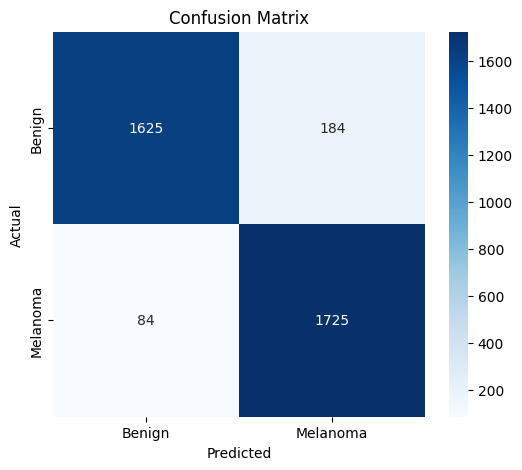

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign","Melanoma"],
    yticklabels=["Benign","Melanoma"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [93]:
from sklearn.metrics import classification_report

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=[
            "Benign",
            "Melanoma"
        ]
    )
)

              precision    recall  f1-score   support

      Benign       0.95      0.90      0.92      1809
    Melanoma       0.90      0.95      0.93      1809

    accuracy                           0.93      3618
   macro avg       0.93      0.93      0.93      3618
weighted avg       0.93      0.93      0.93      3618



In [94]:
from sklearn.metrics import (
    matthews_corrcoef,
    balanced_accuracy_score,
    cohen_kappa_score
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(
        all_labels,
        all_preds
    )
)

print(
    "MCC:",
    matthews_corrcoef(
        all_labels,
        all_preds
    )
)

print(
    "Cohen Kappa:",
    cohen_kappa_score(
        all_labels,
        all_preds
    )
)

Balanced Accuracy: 0.9259259259259259
MCC: 0.8531563806544845
Cohen Kappa: 0.8518518518518519


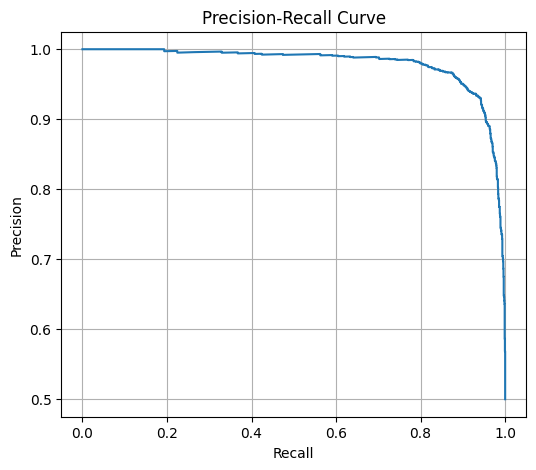

In [95]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, _ = precision_recall_curve(
    all_labels,
    all_probs
)

plt.figure(figsize=(6,5))
plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(True)

plt.show()

In [96]:
train_losses = []
val_losses = []

In [97]:
train_losses.append(train_loss)
val_losses.append(val_loss)

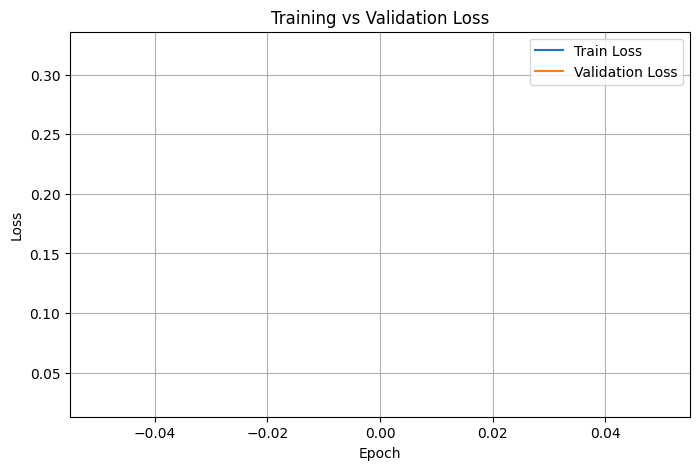

In [98]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [99]:
print(len(train_losses))
print(len(val_losses))

1
1


In [100]:
val_accs = []
val_accs.append(acc)

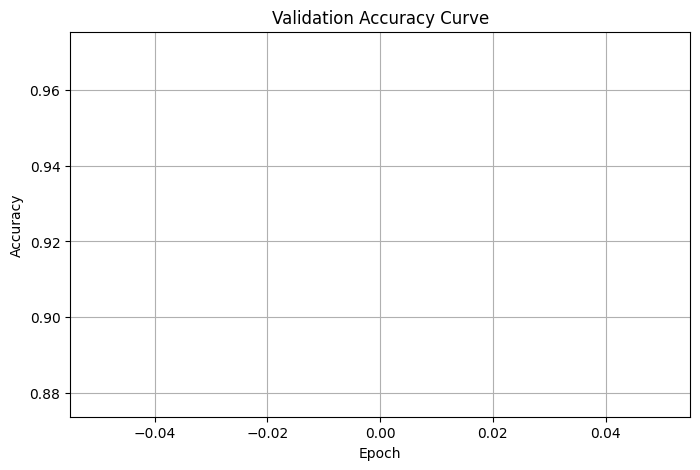

In [101]:
plt.figure(figsize=(8,5))

plt.plot(val_accs)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy Curve")
plt.grid(True)

plt.show()

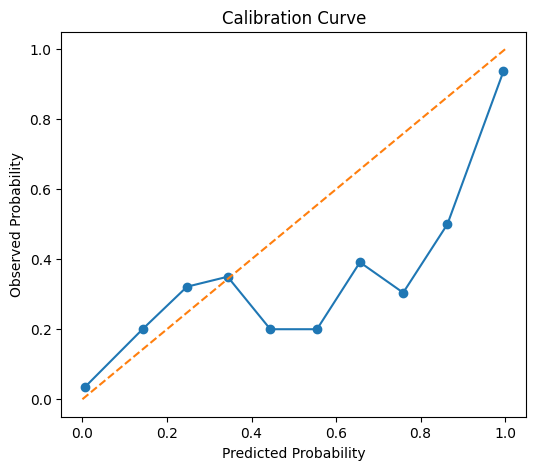

In [102]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    all_labels,
    all_probs,
    n_bins=10
)

plt.figure(figsize=(6,5))

plt.plot(prob_pred, prob_true, marker='o')
plt.plot([0,1],[0,1],'--')

plt.xlabel("Predicted Probability")
plt.ylabel("Observed Probability")
plt.title("Calibration Curve")

plt.show()